# If the data is non-linear, we use Polynomial regression.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [23]:
x = 6 * np.random.rand(200, 1) - 3
y = 0.8 * x**2 + 0.9 * x + 2 + np.random.randn(200, 1)

# y = 0.8x^2 + 0.9x + 2

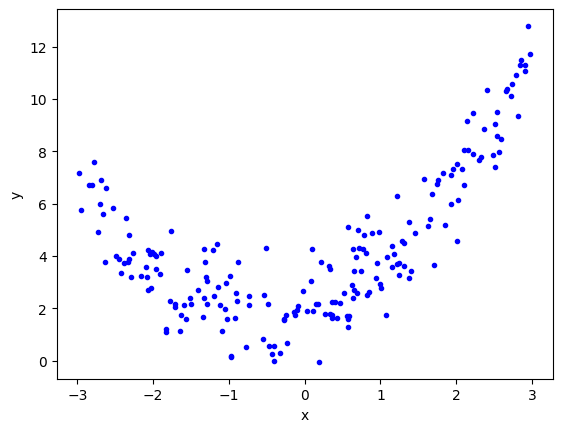

In [24]:
plt.plot(x, y,'b.')
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [25]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [26]:
# Applying Linear regression

lr = LinearRegression()

lr.fit(x_train, y_train)

LinearRegression()

In [27]:
pred = lr.predict(x_test)

print(r2_score(y_test, pred))

0.29223899171577417


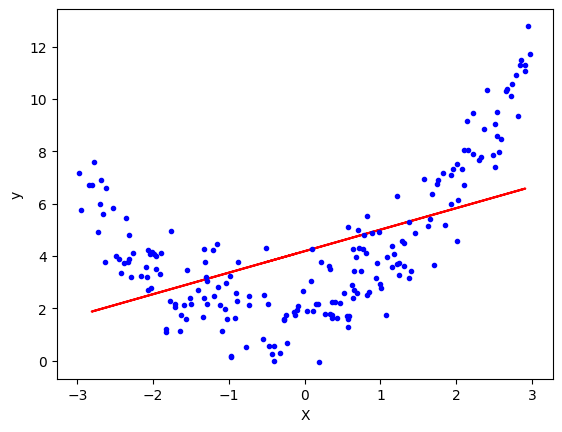

In [28]:
plt.plot(x_train, lr.predict(x_train), color='r')
plt.plot(x, y, "b.")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

# Applying Polynomial Linear Regression

In [40]:
# Extracting polynimial fetures with degree 2

poly = PolynomialFeatures(degree = 2, include_bias = True)

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

In [41]:
print(x_train[0])

print()
print()

print(x_train_poly[0])

[-0.50650435]


[ 1.         -0.50650435  0.25654665]


In [43]:
# Applying linear regression on polynomial featurees

lr = LinearRegression()

lr.fit(x_train_poly, y_train)

pred = lr.predict(x_test_poly)

In [45]:
print(f'r2_score_poly: {r2_score(y_test, pred)}')

r2_score_poly: 0.9238356620371478


In [51]:
print(lr.coef_)

print()

print(lr.intercept_)

[[0.         0.83802975 0.79277623]]

[2.03342204]


In [52]:
x_new=np.linspace(-3, 3, 200).reshape(200, 1)
x_new_poly = poly.transform(x_new)
y_new = lr.predict(x_new_poly)

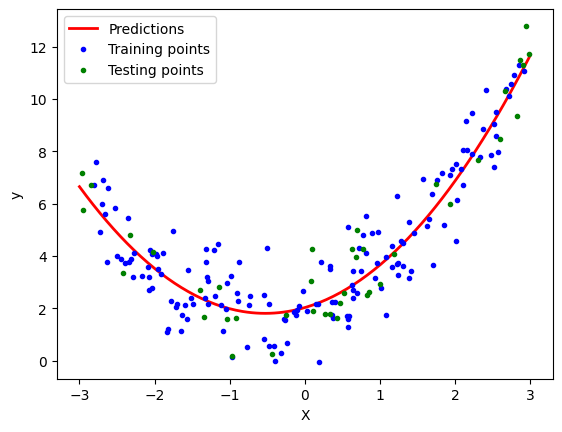

In [53]:
x_new=np.linspace(-3, 3, 200).reshape(200, 1)
x_new_poly = poly.transform(x_new)
y_new = lr.predict(x_new_poly)
plt.plot(x_new, y_new, "r-", linewidth=2, label="Predictions")
plt.plot(x_train, y_train, "b.",label='Training points')
plt.plot(x_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [56]:
def polynomial_regression(degree):
    x_new=np.linspace(-3, 3, 100).reshape(100, 1)
    x_new_poly = poly.transform(x_new)

    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = Pipeline([
            ("poly_features", polybig_features),
            ("std_scaler", std_scaler),
            ("lin_reg", lin_reg),
        ])
    polynomial_regression.fit(x, y)
    y_newbig = polynomial_regression.predict(x_new)
    plt.plot(x_new, y_newbig,'r', label="Degree " + str(degree), linewidth=2)

    plt.plot(x_train, y_train, "b.", linewidth=3)
    plt.plot(x_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-3, 3, 0, 10])
    plt.show()

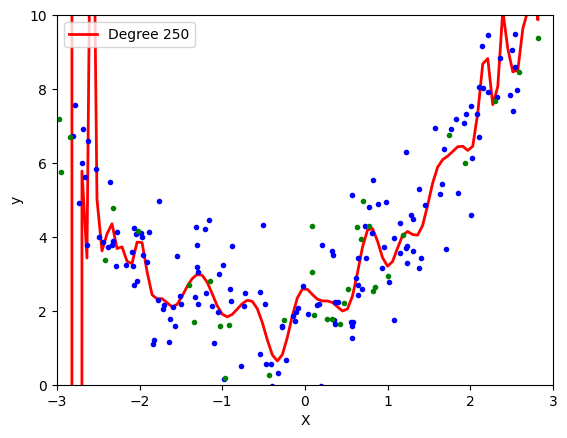

In [73]:
polynomial_regression(250)